💾 Figura_combinacion_omega_Abilene_datos.csv

========== T+5 min · modo A · ω con 'pred' (Results_horas_abilene/results_Arq1_1h_A_W24) · 110 enlaces ==========
WAPE ARIMA: 13.2 %
Chronos: WAPE 13.0 % · gana a ARIMA en 80.9 % de los enlaces
WAPE (%)
ω                   0.00  0.05  0.10  0.15  0.20  0.25  0.30  0.40  0.50  0.60  0.75  1.00
Modelo                                                                                    
Arch1               12.3  12.3  12.5  12.7  13.0  13.3  13.7  14.6  15.6  16.7  18.6  22.2
Arch2               12.3  12.3  12.5  12.7  13.0  13.3  13.7  14.6  15.6  16.7  18.6  22.2
Arch3               12.3  12.3  12.5  12.7  12.9  13.3  13.6  14.5  15.6  16.7  18.6  22.2
Arch4               12.4  12.4  12.6  12.8  13.0  13.4  13.7  14.6  15.6  16.8  18.7  22.2
Arch1 (real, cota)  12.3  12.1  12.0  11.9  11.9  11.9  11.9  12.0  12.1  12.4  13.0  14.3
% de enlaces que ganan a Chronos (criterio WAPE)
ω                   0.00  0.05  0.10  0.15  0.20  0.25  0.30  0.4

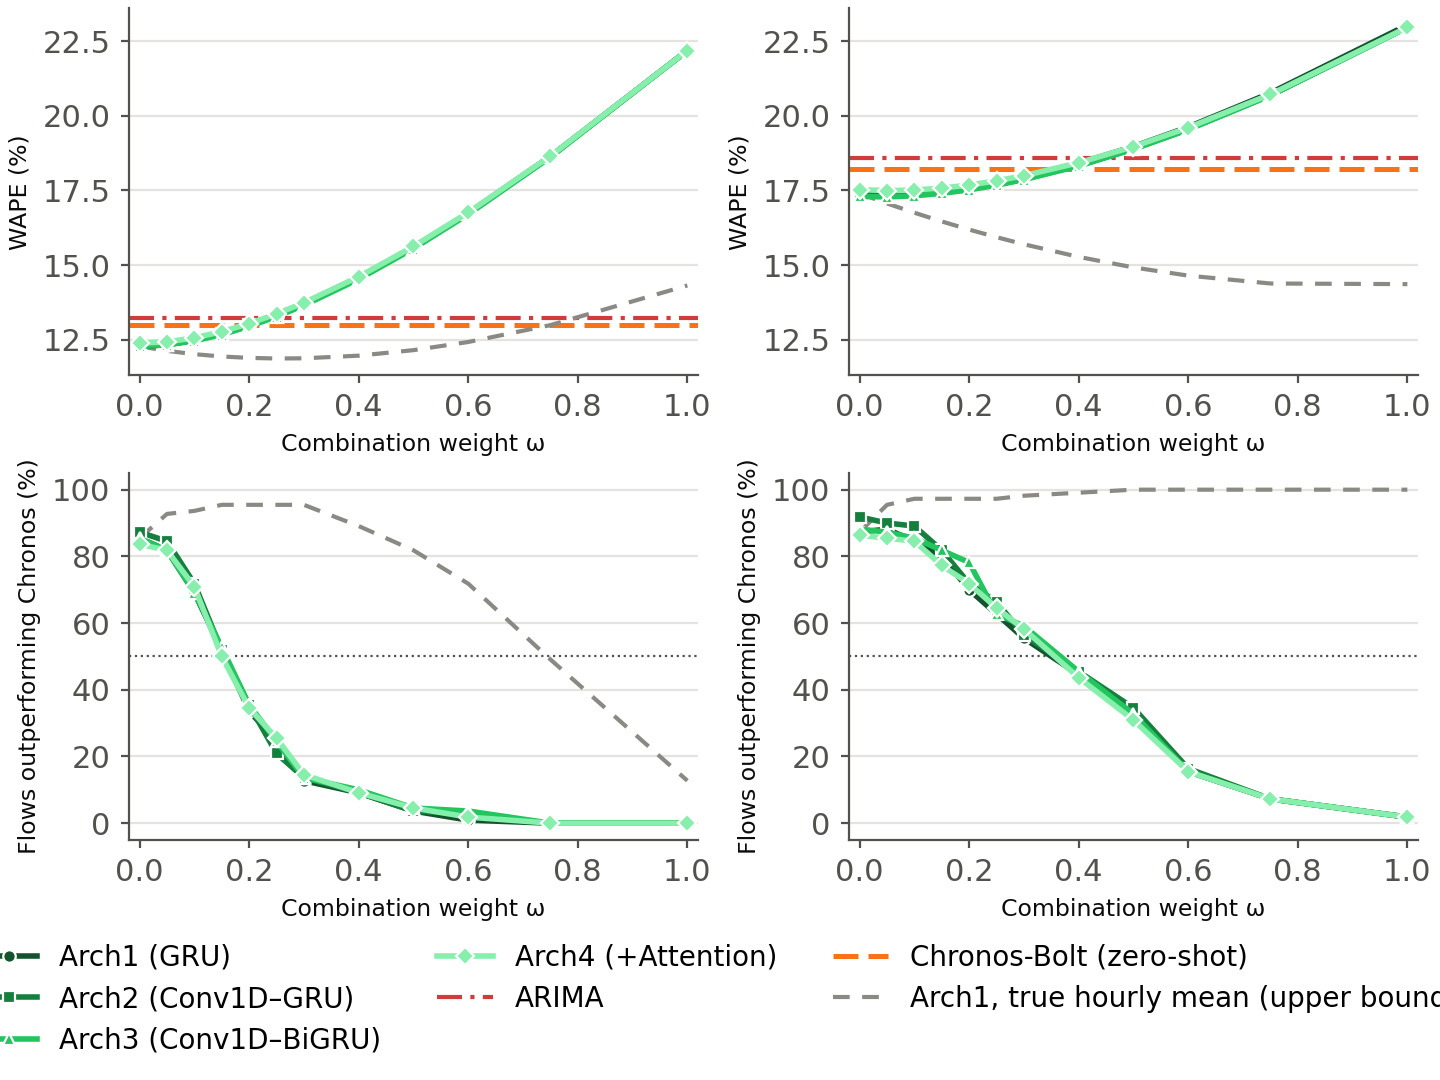

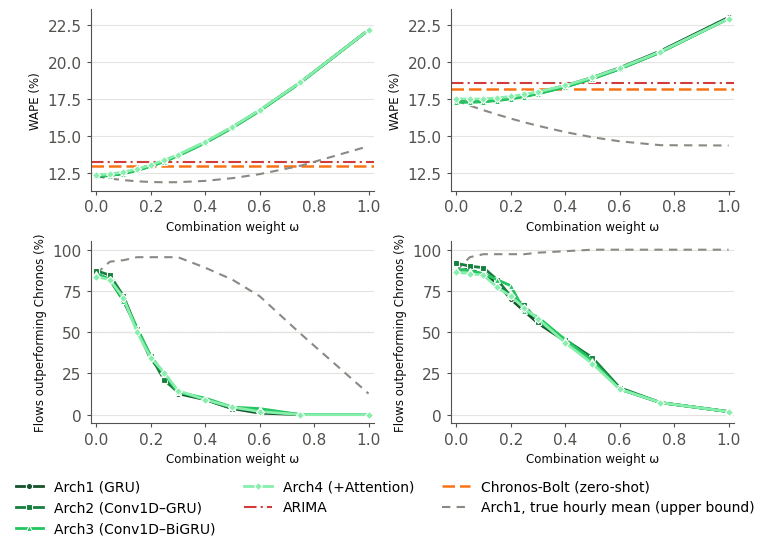

In [6]:
# ============================================================
# Figura_combinacion_omega_Abilene.py — v2.12 (Abilene)
#   1. ROOT_RESULTS, DIR_BASE, SALIDA y CHRONOS de Abilene.
#   2. TRIGGER en Mbit/s (unidad de SNDlib para Abilene).
#   3. ARIMA en pasos de 5 min: ARIMA_t+1 (T+5) y ARIMA_t+3 (T+15).
#   4. Arquitecturas en tonos de verde.
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT_RESULTS = "Results_min_Abilene"
DIR_BASE     = "Results_min_Abilene/results_baselines_5min"
CARPETA      = "results_Arq{ID}_{H}m_{MODO}_W60_w00_H{H}"
IDS          = [1, 2, 3, 4]
HORIZONTES   = [5, 15]
MODO         = "A"
TRIGGER      = 0.001         # Mbit/s (= 1000 bps, como BRAIN). Antes: 10
OMEGAS       = [0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30,0.4, 0.50, 0.6, 0.75, 1.0]
FUENTE       = "pred"     # pred | movil60 | hora_ant   (sin fuga)
FUENTE_COTA  = "real"        # línea gris (Arq1). None para no dibujarla
CRITERIO     = "WAPE"        # WAPE / MAE (mismo resultado por enlace) o MAPE para decidir si gana. Antes: MAPE
SALIDA       = "Figura_combinacion_omega_Abilene"
DIR_PLOTS    = "plots"       # aquí se guarda cada gráfica en un PDF
TAM_EJES     = 11            # tamaño de los números de los ejes
TAM_LEYENDA  = 10            # tamaño de la leyenda
CHRONOS      = "Results_min_Abilene/results_chronos-bolt-small_C12_{H}m"   # None para no dibujarla
# Predicción horaria para FUENTE = "pred" (None = la guardada en el test):
DIR_HORARIO  = "Results_horas_abilene/results_Arq1_1h_A_W24"   # Arch1_A W24 horario (como dice el paper)
REFERENCIA   = "Chronos"     # Chronos | ARIMA : contra quién se cuentan las victorias en (c)/(d)
#   otros: "Results_horas_v11/results_Arq3_1h_B_W24", "Results_horas_v11/results_chronos-bolt-small_C168_1h", …


def curvas(ID, H, fuente):
    """WAPE y % de enlaces que ganan a ARIMA para cada ω, y WAPE de ARIMA."""
    d = os.path.join(ROOT_RESULTS, CARPETA.format(ID=ID, H=H, MODO=MODO))
    if not os.path.isdir(d):
        print(f"⚠️ falta {d}")
        return None
    pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
    col_h = f"Hora_{fuente}"
    al_vuelo = fuente == "pred" and DIR_HORARIO is not None
    ph = "test_" + os.path.basename(DIR_HORARIO.rstrip("/")).removeprefix("results_") + "_" if al_vuelo else None
    se, sy, se_a, se_c = np.zeros(len(OMEGAS)), 0.0, 0.0, 0.0
    gana, n, gana_c = np.zeros(len(OMEGAS)), 0, 0
    dc = CHRONOS.format(H=H) if CHRONOS else None
    pc = "test_" + os.path.basename(dc).removeprefix("results_") + "_" if dc else None
    for f in sorted(os.listdir(d)):
        if not (f.startswith(pref) and f.endswith(".csv")):
            continue
        e = f[len(pref):-4]
        fb = os.path.join(DIR_BASE, f"test_results_{e}_baselines.csv")
        if not os.path.exists(fb):
            continue
        j = pd.read_csv(os.path.join(d, f), parse_dates=["timestamp"]).set_index("timestamp")
        if al_vuelo:
            fh = os.path.join(DIR_HORARIO, f"{ph}{e}.csv")
            if not os.path.exists(fh):
                print(f"⚠️ falta horario {fh}: enlace fuera"); continue
            m = pd.read_csv(fh, parse_dates=["timestamp"]).set_index("timestamp")["Prediccion"]
            t_obs = j.index - pd.Timedelta(minutes=H)                     # último minuto observado
            j[col_h] = m.reindex(t_obs.ceil("h")).ffill().bfill().values
        elif col_h not in j.columns:
            print(f"❌ {f} no tiene la columna {col_h}"); return None
        b = pd.read_csv(fb, parse_dates=["timestamp"]).set_index("timestamp")
        j = j[["Realidad", "Prediccion", col_h]].join(
            b[[f"ARIMA_t+{H // 5}"]].rename(columns={f"ARIMA_t+{H // 5}": "ARIMA"}), how="inner")   # pasos de 5 min
        if dc:
            fc = os.path.join(dc, f"{pc}{e}.csv")
            if not os.path.exists(fc):
                print(f"⚠️ falta Chronos {fc}: enlace fuera"); continue
            c = pd.read_csv(fc, parse_dates=["timestamp"]).set_index("timestamp")[["Prediccion"]]
            j = j.join(c.rename(columns={"Prediccion": "Chronos"}), how="inner")
        j = j.dropna()
        j = j[j["Realidad"] > TRIGGER]
        if j.empty:
            continue
        y, p, h, a = (j[c].values for c in ["Realidad", "Prediccion", col_h, "ARIMA"])
        medida = (lambda e: np.mean(e / y)) if CRITERIO == "MAPE" else (lambda e: e.mean())
        ea = np.abs(y - a)
        err_a = medida(ea)
        sy += y.sum(); se_a += ea.sum(); n += 1
        err_ref = err_a
        if dc:
            ec = np.abs(y - j["Chronos"].values)
            se_c += ec.sum(); gana_c += medida(ec) < err_a
            if REFERENCIA == "Chronos":
                err_ref = medida(ec)
        for k, w in enumerate(OMEGAS):
            err = np.abs(y - ((1 - w) * p + w * h))
            se[k] += err.sum()
            gana[k] += medida(err) < err_ref
    if n == 0:
        return None
    return (100 * se / sy, 100 * gana / n, n, 100 * se_a / sy,
            100 * se_c / sy if dc else None, 100 * gana_c / n if dc else None)


# ---------------- cálculo ----------------
if REFERENCIA == "Chronos" and not CHRONOS:
    raise SystemExit("❌ REFERENCIA = 'Chronos' necesita CHRONOS")
datos, filas = {}, []
for H in HORIZONTES:
    for ID in IDS:
        r = curvas(ID, H, FUENTE)
        if r is not None:
            datos[(H, ID)] = r
            filas += [{"H": H, "Arq": ID, "fuente": FUENTE, "ω": w, "WAPE": r[0][k],
                       "% gana ARIMA": r[1][k], "enlaces": r[2]} for k, w in enumerate(OMEGAS)]
    if FUENTE_COTA:
        r = curvas(1, H, FUENTE_COTA)
        if r is not None:
            datos[(H, "cota")] = r
            filas += [{"H": H, "Arq": 1, "fuente": FUENTE_COTA, "ω": w, "WAPE": r[0][k],
                       "% gana ARIMA": r[1][k], "enlaces": r[2]} for k, w in enumerate(OMEGAS)]
tabla = pd.DataFrame(filas)
tabla[["WAPE", "% gana ARIMA"]] = tabla[["WAPE", "% gana ARIMA"]].round(1)
tabla.to_csv(f"{SALIDA}_datos.csv", index=False)
print(f"💾 {SALIDA}_datos.csv")

# ---------------- por pantalla ----------------
pd.set_option("display.width", 250)
for H in HORIZONTES:
    t = tabla[tabla["H"] == H]
    idx = t["fuente"].map(lambda f: "cota" if f == FUENTE_COTA and FUENTE_COTA != FUENTE else "") + \
          t["Arq"].map(lambda a: f"Arch{a}")
    t = t.assign(Modelo=idx.str.replace("cotaArch1", f"Arch1 ({FUENTE_COTA}, cota)"))
    print(f"\n========== T+{H} min · modo {MODO} · ω con '{FUENTE}'"
          + (f" ({DIR_HORARIO})" if FUENTE == "pred" and DIR_HORARIO else "")
          + f" · {t['enlaces'].iloc[0]} enlaces ==========")
    if (H, 1) in datos:
        print(f"WAPE ARIMA: {datos[(H, 1)][3]:.1f} %")
        if datos[(H, 1)][4] is not None:
            print(f"Chronos: WAPE {datos[(H, 1)][4]:.1f} % · gana a ARIMA en {datos[(H, 1)][5]:.1f} % de los enlaces")
    print("WAPE (%)")
    print(t.pivot_table(index="Modelo", columns="ω", values="WAPE", sort=False).to_string())
    print(f"% de enlaces que ganan a {REFERENCIA} (criterio {CRITERIO})")
    print(t.pivot_table(index="Modelo", columns="ω", values="% gana ARIMA", sort=False).to_string())

# ---------------- figura ----------------
NOMBRES = {1: "Arch1 (GRU)", 2: "Arch2 (Conv1D–GRU)", 3: "Arch3 (Conv1D–BiGRU)", 4: "Arch4 (+Attention)"}
COLOR   = {1: "#14532d", 2: "#15803d", 3: "#22c55e", 4: "#86efac"}   # verde, de oscuro a claro
MARCA   = {1: "o", 2: "s", 3: "^", 4: "D"}
TINTA, TINTA2, REJILLA, GRIS, ROJO = "#0b0b0b", "#52514e", "#e4e3df", "#8a8984", "#d03b3b"
NARANJA = "#f97316"
COTA_TXT = {"real": "Arch1, true hourly mean (upper bound)", "pred": "Arch1, hourly forecast",
            "movil60": "Arch1, last-60-min mean", "hora_ant": "Arch1, last complete hour"}

# mismos límites Y en las dos gráficas de cada columna (mín y máx de las dos)
LIM = []
for col in (0, 1):
    v = [x for k, r in datos.items() for x in r[col]]
    if col == 0:
        v += [datos[(H, 1)][3] for H in HORIZONTES if (H, 1) in datos]
    v += [datos[(H, 1)][4 + col] for H in HORIZONTES
          if (H, 1) in datos and datos[(H, 1)][4 + col] is not None and (col == 0 or REFERENCIA == "ARIMA")]
    lo, hi = min(v), max(v)
    m = 0.05 * (hi - lo)
    LIM.append((lo - m, hi + m))

def panel(ax, H, col):
    ylab = ["WAPE (%)", f"Flows outperforming {REFERENCIA} (%)"][col]
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(TINTA2); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=TINTA2, labelsize=TAM_EJES, length=3)
    ax.yaxis.grid(True, color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)

    if col == 0 and (H, 1) in datos:
        ax.axhline(datos[(H, 1)][3], color=ROJO, linewidth=1.5, linestyle=(0, (6, 2, 1, 2)),
                   label="ARIMA", zorder=1)
    if (H, 1) in datos and datos[(H, 1)][4 + col] is not None and (col == 0 or REFERENCIA == "ARIMA"):
        ax.axhline(datos[(H, 1)][4 + col], color=NARANJA, linewidth=1.8, linestyle=(0, (5, 2)),
                   label="Chronos-Bolt (zero-shot)", zorder=1)
    if (H, "cota") in datos:
        ax.plot(OMEGAS, datos[(H, "cota")][col], color=GRIS, linewidth=1.5, linestyle=(0, (4, 3)),
                label=COTA_TXT[FUENTE_COTA], zorder=1)
    for ID in IDS:
        if (H, ID) in datos:
            ax.plot(OMEGAS, datos[(H, ID)][col], color=COLOR[ID], marker=MARCA[ID], markersize=4.5,
                    linewidth=2, label=NOMBRES[ID], zorder=2,
                    markeredgecolor="white", markeredgewidth=0.8)
    if col == 1:
        ax.axhline(50, color=TINTA2, linewidth=0.8, linestyle=":", zorder=0)
    ax.set_ylim(*LIM[col])
    ax.set_xlim(-0.02, 1.02)
    ax.set_xlabel("Combination weight ω", fontsize=8.5, color=TINTA)
    ax.set_ylabel(ylab, fontsize=8.5, color=TINTA)


def leyenda_ordenada(h, l):
    orden = [i for i, t in enumerate(l) if t in NOMBRES.values()] + \
            [i for i, t in enumerate(l) if t not in NOMBRES.values()]
    return [h[i] for i in orden], [l[i] for i in orden]


# ---- cada gráfica en su propio PDF (DIR_PLOTS) ----
# letras: (a) WAPE T+5, (b) WAPE T+15, (c) gana T+5, (d) gana T+15
os.makedirs(DIR_PLOTS, exist_ok=True)
for col, nom in enumerate(["WAPE", f"gana_{REFERENCIA}"]):
    for k, H in enumerate(HORIZONTES):
        letra = chr(97 + len(HORIZONTES) * col + k)
        f1, ax = plt.subplots(figsize=(4.4, 3.6), constrained_layout=True)
        panel(ax, H, col)
        hh, ll = leyenda_ordenada(*ax.get_legend_handles_labels())
        ll = [t.replace(" (upper bound)", "\n(upper bound)") for t in ll]   # que quepa en 2 columnas
        f1.legend(hh, ll, loc="outside lower center", ncol=2, frameon=False, fontsize=TAM_LEYENDA,
                  handlelength=1.6, columnspacing=1.0, handletextpad=0.5)
        ruta = os.path.join(DIR_PLOTS, f"{SALIDA}_{letra}_T{H}_{nom}.pdf")
        f1.savefig(ruta)
        plt.close(f1)
        print(f"💾 {ruta}")

# ---- figura completa 2×2: fila 1 = WAPE (a, b), fila 2 = % que ganan (c, d) ----
fig, axes = plt.subplots(2, len(HORIZONTES), figsize=(7.2, 5.4),
                         constrained_layout=True, squeeze=False)
for col in (0, 1):
    for k, H in enumerate(HORIZONTES):
        panel(axes[col, k], H, col)

h, l = axes[0, 0].get_legend_handles_labels()
h2, l2 = axes[1, 0].get_legend_handles_labels()
h += [x for x, t in zip(h2, l2) if t not in l]; l += [t for t in l2 if t not in l]
fig.legend(*leyenda_ordenada(h, l), loc="outside lower center",
           ncol=3, frameon=False, fontsize=TAM_LEYENDA)
fig.savefig(f"{SALIDA}.pdf")
fig.savefig(f"{SALIDA}.png", dpi=200)
print(f"💾 {SALIDA}.pdf / .png")
try:                                    # en Jupyter se muestra siempre, aunque el backend sea Agg
    from IPython.display import display, Image
    get_ipython()
    display(Image(filename=f"{SALIDA}.png"))
except NameError:
    plt.show()

In [2]:
# ============================================================
# Comprobar_Abilene_datos.py — v1.2
# v1.2: - Unidad: los valores de SNDlib para Abilene están en Mbit/s (mediana ~10, P99 ~137).
#         Se comparan dos umbrales: 10 Mbit/s (el actual) y 0.001 Mbit/s (= 1000 bps, el de BRAIN):
#         % de instantes de test que quita, % del volumen de tráfico que quita y flujos que quedan.
#       - CV con los dos umbrales.
#       - Huecos: SOLO dentro del rango de fechas de abilene_FINAL_5min.csv (la v1.1 miraba todo el
#         fichero bruto, que llega más lejos que el CSV final, y el veredicto "QUITADOS" podía ser falso).
#         Además mira si el CSV final tiene saltos de tiempo (> 5 min) entre filas.
# v1.1: BRAIN solo hace falta para comparar el CV; si no se encuentra, se salta esa parte.
# Datos para la Sección 5.5 (Abilene). No usa GPU.
# Ejecutar desde la carpeta de los CSV de Abilene:  python Comprobar_Abilene_datos.py
# ============================================================
import os
import numpy as np
import pandas as pd

AB_BRUTO   = "abilene_bruto_5min.csv"
AB_5MIN    = "abilene_FINAL_5min.csv"
BR_1MIN    = ["brain_FINAL_1min.csv",                        # rutas posibles de BRAIN (la primera que exista)
              "../brain_FINAL_1min.csv",
              "~/SDN/LSTM_brain_revision/brain_FINAL_1min.csv"]
CORTE_AB   = "2004-08-08 00:00:00"
CORTE_BR   = "2013-03-14 00:00:00"
UMBRALES_AB = [10, 0.001]   # Mbit/s: el actual y el equivalente a los 1000 bps de BRAIN
UMBRAL_BR  = 1000           # bps
NO_FLUJO   = ["timestamp", "hour", "day_of_week", "hour_sin", "hour_cos", "day_sin", "day_cos", "is_weekend"]


def flujos(df, sin_intra=False):
    c = [x for x in df.columns if x not in NO_FLUJO]
    if sin_intra:
        c = [x for x in c if x.split("_")[0] != x.split("_")[-1]]
    return c


def stats_por_flujo(df, cols, umbral):
    filas = []
    for e in cols:
        y = df[e].values.astype(float)
        y = y[y > umbral]
        if len(y) < 2 or y.mean() <= 0:
            continue
        filas.append({"flujo": e, "CV%": 100 * y.std() / y.mean(), "PeakRatio": y.max() / y.mean()})
    return pd.DataFrame(filas)


def resumen(nombre, s):
    print(f"   {nombre:<30} flujos={len(s):>3} | CV% mediana {s['CV%'].median():6.1f} "
          f"(P25–P75 {s['CV%'].quantile(.25):.1f}–{s['CV%'].quantile(.75):.1f}) | "
          f"PeakRatio mediana {s['PeakRatio'].median():5.1f}")


def saltos(ts):
    d = pd.Series(pd.DatetimeIndex(ts)).sort_values().diff().dropna()
    s = d[d > pd.Timedelta("5min")]
    return len(s), (s.max() if len(s) else pd.Timedelta(0)), int((s / pd.Timedelta("5min") - 1).sum())


# ---------------- Abilene: unidad y umbral ----------------
ab = pd.read_csv(AB_5MIN, parse_dates=["timestamp"])
cab = flujos(ab, sin_intra=True)
abt = ab[ab["timestamp"] >= CORTE_AB]
X = abt[cab].values.astype(float)
v = X.ravel()

print("=" * 78)
print("1. UMBRAL DE ABILENE (periodo de test, flujos entre nodos; valores en Mbit/s)")
print(f"   {len(cab)} flujos | test {abt['timestamp'].min()} → {abt['timestamp'].max()} ({len(abt)} instantes)")
print(f"   mediana {np.median(v):.3g} | P90 {np.percentile(v, 90):.3g} | P99 {np.percentile(v, 99):.3g} | máx {v.max():.3g}")
for u in UMBRALES_AB:
    fuera = X <= u
    print(f"   x_t > {u:<6g} Mbit/s: quita {100 * fuera.mean():5.1f} % de los instantes y "
          f"{100 * X[fuera].sum() / X.sum():4.1f} % del volumen | flujos con datos: {(~fuera).any(axis=0).sum()}")

# ---------------- suavidad ----------------
print("\n2. SUAVIDAD (CV y PeakRatio por flujo, periodo de test)")
ruta_br = next((os.path.expanduser(r) for r in BR_1MIN if os.path.exists(os.path.expanduser(r))), None)
if ruta_br:
    br = pd.read_csv(ruta_br, parse_dates=["timestamp"])
    cbr = flujos(br)
    brt = br[br["timestamp"] >= CORTE_BR]
    br5 = brt.set_index("timestamp")[cbr].resample("5min").mean().reset_index()
    resumen(f"BRAIN 1 min (> {UMBRAL_BR} bps)", stats_por_flujo(brt, cbr, UMBRAL_BR))
    resumen(f"BRAIN 5 min (> {UMBRAL_BR} bps)", stats_por_flujo(br5, cbr, UMBRAL_BR))
else:
    print("   ⚠️ no encuentro brain_FINAL_1min.csv: pon su ruta en BR_1MIN para comparar con BRAIN")
for u in UMBRALES_AB:
    resumen(f"Abilene 5 min (> {u:g} Mbit/s)", stats_por_flujo(abt, cab, u))

# ---------------- huecos, dentro del rango del CSV final ----------------
ini, fin = ab["timestamp"].min(), ab["timestamp"].max()
bruto = pd.read_csv(AB_BRUTO, parse_dates=["timestamp"]).drop_duplicates("timestamp")
tsb = pd.DatetimeIndex(bruto["timestamp"])
tsf = pd.DatetimeIndex(ab["timestamp"])

print(f"\n3. HUECOS (solo dentro del rango del CSV final: {ini} → {fin})")
print(f"   fichero bruto completo: {tsb.min()} → {tsb.max()}")
for nombre, a in [("rango del CSV final", ini), ("periodo de test", pd.Timestamp(CORTE_AB))]:
    rej = pd.date_range(a, fin, freq="5min")
    falta = rej.difference(tsb[(tsb >= a) & (tsb <= fin)])
    interp = falta.isin(tsf).sum()
    print(f"   {nombre}: faltan en el bruto {len(falta)} de {len(rej)} instantes ({100 * len(falta) / len(rej):.2f} %)"
          f" → {interp} están en el CSV final (interpolados) y {len(falta) - interp} no (quitados)")
sub = bruto[(bruto["timestamp"] >= ini) & (bruto["timestamp"] <= fin)]
print(f"   celdas NaN en los instantes presentes del bruto (antes de agrupar ATLA): "
      f"{100 * sub.drop(columns='timestamp').isna().values.mean():.2f} %")
for nombre, t in [("CSV final", tsf), ("CSV final, test", tsf[tsf >= pd.Timestamp(CORTE_AB)])]:
    n, mx, pasos = saltos(t)
    print(f"   {nombre}: {n} saltos de tiempo > 5 min entre filas ({pasos} instantes sin fila), el mayor de {mx}")
print("=" * 78)

1. UMBRAL DE ABILENE (periodo de test, flujos entre nodos; valores en Mbit/s)
   110 flujos | test 2004-08-08 00:00:00 → 2004-08-19 23:55:00 (3456 instantes)
   mediana 10.1 | P90 48 | P99 137 | máx 1.88e+03
   x_t > 10     Mbit/s: quita  49.6 % de los instantes y  9.6 % del volumen | flujos con datos: 101
   x_t > 0.001  Mbit/s: quita   2.2 % de los instantes y  0.0 % del volumen | flujos con datos: 110

2. SUAVIDAD (CV y PeakRatio por flujo, periodo de test)
   BRAIN 1 min (> 1000 bps)       flujos= 81 | CV% mediana  131.2 (P25–P75 107.3–179.1) | PeakRatio mediana  13.9
   BRAIN 5 min (> 1000 bps)       flujos= 81 | CV% mediana  119.3 (P25–P75 94.9–154.4) | PeakRatio mediana   7.8
   Abilene 5 min (> 10 Mbit/s)    flujos=101 | CV% mediana   32.7 (P25–P75 22.3–44.0) | PeakRatio mediana   2.8
   Abilene 5 min (> 0.001 Mbit/s) flujos=110 | CV% mediana   55.9 (P25–P75 40.2–88.9) | PeakRatio mediana   5.2

3. HUECOS (solo dentro del rango del CSV final: 2004-05-01 00:00:00 → 2004-08-19 23

In [7]:
# ============================================================
# Tests_estadisticos.py — v1.0
# Tests estadísticos para R4.8 / R5.7 / R1.5 (no usa GPU, solo lee los CSV de test guardados).
#
# Qué hace, para cada comparación "modelo frente a referencia" sobre los flujos:
#   1. WAPE de cada flujo para los dos modelos, en los mismos instantes que las tablas y figuras.
#   2. Test de Wilcoxon de rangos con signo, pareado por flujo (bilateral): ¿las diferencias de
#      WAPE por flujo están sistemáticamente a un lado? No supone normalidad.
#   3. Tamaño del efecto:
#        - mediana de la diferencia de WAPE por flujo (referencia − modelo, en puntos; > 0 = el
#          modelo es mejor) con IC del 95 % por bootstrap sobre los flujos;
#        - correlación biserial de rangos r (de −1 a 1; > 0 = el modelo es mejor).
#   4. Diferencia del WAPE GLOBAL (Σ|e|/Σy, el de las tablas) con IC del 95 % por bootstrap sobre
#      los flujos: dice si una diferencia como la de Chronos frente a Arch1_A (0.5 puntos) es real.
#   5. Corrección de Holm por comparaciones múltiples, dentro de cada familia (las comparaciones
#      de una misma arquitectura en esa parte) y, como referencia, sobre toda la parte.
#
# Partes (cada una se salta si no está su carpeta; BRAIN y Abilene van en carpetas distintas):
#   "min"     BRAIN, minutos, ω = 0: Arch1–4 (A) frente a ARIMA y Chronos, T+5 y T+15.
#             Instantes comunes de las 8 arquitecturas + ARIMA + Chronos (= Tablas 4–6 y apéndice).
#   "omega"   BRAIN, combinación jerárquica de Arch1_A con la hora de Arch1_A W24 (= Figs. 2 y 3):
#             cada ω de OMEGAS frente a ω = 0 y frente a Chronos, T+5 y T+15.
#   "hora"    BRAIN, nivel horario, W = 24: las 8 configuraciones frente a ARIMA y Chronos (= Tablas 2 y 3).
#   "abilene" Abilene, ω = 0: Arch1–4 (A) frente a ARIMA y Chronos, T+5 y T+15 (= Fig. 4 con ω = 0).
#
# Ejecutar desde la carpeta de los resultados (la de BRAIN o la de Abilene):
#     python Tests_estadisticos.py
# Salida: tablas por pantalla y Tests_estadisticos.csv
# ============================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, rankdata

PARTES  = ["min", "omega", "hora", "abilene"]
B_BOOT  = 5000          # remuestras bootstrap
SEMILLA = 0
SALIDA  = "Tests_estadisticos.csv"
IDS     = [1, 2, 3, 4]

MIN = dict(ROOT="Results_min_Base", BASE="Results_min_Base/results_baselines_1min",
           CARPETA="results_Arq{ID}_{H}m_{M}_W60_w00_H{H}", CHRONOS="results_chronos-bolt-small_C60_{H}m",
           ARIMA="ARIMA_t+{H}", TRIGGER=1000, HORIZONTES=[5, 15], MASCARA=["A", "B"])
OMEGA = dict(DIR_HORARIO="Results_horas/results_Arq1_1h_A_W24", OMEGAS=[0.05, 0.10, 0.15, 0.20])
HORA = dict(ROOT="Results_horas", BASE="Results_horas/results_baselines_1h",
            CARPETA="results_Arq{ID}_1h_{M}_W{W}", CHRONOS="results_chronos-bolt-small_C{W}_1h",
            ARIMA="ARIMA_t+1", TRIGGER=1000, W=24, MASCARA=["A", "B"])
ABILENE = dict(ROOT="Results_min_Abilene", BASE="Results_min_Abilene/results_baselines_5min",
               CARPETA="results_Arq{ID}_{H}m_A_W60_w00_H{H}", CHRONOS="results_chronos-bolt-small_C12_{H}m",
               ARIMA="ARIMA_t+{P}", TRIGGER=0.001, HORIZONTES=[5, 15])      # P = H/5 pasos de 5 min

rng = np.random.default_rng(SEMILLA)


# ---------------- utilidades ----------------
def es_flujo(e):
    p = e.split("_")
    return len(p) == 2 and all(len(x) >= 2 for x in p)


def flujos_chronos(root, carpeta):
    d = os.path.join(root, carpeta)
    pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
    return {f[len(pref):-4]: os.path.join(d, f) for f in sorted(os.listdir(d))
            if f.startswith(pref) and f.endswith(".csv") and es_flujo(f[len(pref):-4])}


def ruta_test(root, carpeta, e):
    return os.path.join(root, carpeta, f"test_{carpeta.removeprefix('results_')}_{e}.csv")


def leer(f, col, nombre):
    return pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[[col]].rename(columns={col: nombre})


def holm(p):
    p = np.asarray(p, float)
    out = np.full(len(p), np.nan)
    ok = ~np.isnan(p)
    q, m = p[ok], ok.sum()
    orden = np.argsort(q)
    adj, run = np.empty(m), 0.0
    for k, j in enumerate(orden):
        run = max(run, min(1.0, (m - k) * q[j]))
        adj[j] = run
    out[ok] = adj
    return out


def comparar(se_m, se_r, sy):
    """se_m, se_r: Σ|e| por flujo del modelo y de la referencia; sy: Σy por flujo (mismos instantes)."""
    se_m, se_r, sy = map(np.asarray, (se_m, se_r, sy))
    d = 100 * (se_r - se_m) / sy                     # > 0: el modelo tiene menor WAPE en ese flujo
    n = len(d)
    nz = d[d != 0]
    if len(nz) == 0:
        p, r = np.nan, 0.0
    else:
        p = wilcoxon(nz).pvalue
        rk = rankdata(np.abs(nz))
        r = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum()
    idx = rng.integers(0, n, size=(B_BOOT, n))
    med_b = np.median(d[idx], axis=1)
    glob = 100 * (se_r.sum() - se_m.sum()) / sy.sum()
    glob_b = 100 * (se_r[idx].sum(1) - se_m[idx].sum(1)) / sy[idx].sum(1)
    return {"N": n, "Gana": int((d > 0).sum()), "Pierde": int((d < 0).sum()),
            "Pct_gana": round(100 * (d > 0).mean(), 1),
            "dWAPE_flujo_med": np.median(d), "IC_lo": np.percentile(med_b, 2.5), "IC_hi": np.percentile(med_b, 97.5),
            "r_rb": r, "p": p,
            "dWAPE_global": glob, "IC_glob_lo": np.percentile(glob_b, 2.5), "IC_glob_hi": np.percentile(glob_b, 97.5)}


def acumular(j, cols):
    y = j["Realidad"].values
    return {c: np.abs(y - j[c].values).sum() for c in cols}, y.sum()


# ---------------- partes ----------------
def parte_min():
    C, filas = MIN, []
    for H in C["HORIZONTES"]:
        se, sy = {}, []
        for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(H=H)).items():
            j = None
            for ID in IDS:
                for M in C["MASCARA"]:
                    f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=ID, H=H, M=M), e)
                    if os.path.exists(f):
                        t = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
                        t = t.rename(columns={"Prediccion": f"Arch{ID}_{M}"})
                        j = t if j is None else j.join(t.drop(columns="Realidad"), how="inner")
            fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
            if j is None or not os.path.exists(fb):
                continue
            j = j.join(leer(fb, C["ARIMA"].format(H=H), "ARIMA"), how="inner").join(
                leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
            j = j[j["Realidad"] > C["TRIGGER"]]
            if j.empty:
                continue
            s, y = acumular(j, [c for c in j.columns if c != "Realidad"])
            for k, v in s.items():
                se.setdefault(k, []).append(v)
            sy.append(y)
        print(f"   min T+{H}: {len(sy)} flujos | WAPE global: " +
              " | ".join(f"{k} {100 * sum(v) / sum(sy):.1f}" for k, v in sorted(se.items()) if k.endswith("_A") or k in ("ARIMA", "Chronos")))
        for ID in IDS:
            m = f"Arch{ID}_A"
            if m not in se:
                continue
            for ref in ("ARIMA", "Chronos"):
                filas.append({"Parte": "min", "Horizonte": f"T+{H}", "Modelo": m, "Referencia": ref,
                              "Familia": f"min_{m}", **comparar(se[m], se[ref], sy)})
    return filas


def parte_omega():
    C, filas = MIN, []
    dh = OMEGA["DIR_HORARIO"]
    ph = "test_" + os.path.basename(dh.rstrip("/")).removeprefix("results_") + "_"
    for H in C["HORIZONTES"]:
        cols = ["w0"] + [f"w{w:.2f}" for w in OMEGA["OMEGAS"]]
        se, sy = {}, []
        for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(H=H)).items():
            f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=1, H=H, M="A"), e)
            fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
            fh = os.path.join(dh, f"{ph}{e}.csv")
            if not (os.path.exists(f) and os.path.exists(fb) and os.path.exists(fh)):
                continue
            j = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
            m = pd.read_csv(fh, parse_dates=["timestamp"]).set_index("timestamp")["Prediccion"]
            t_obs = j.index - pd.Timedelta(minutes=H)                  # como Figura_combinacion_omega
            j["Hora"] = m.reindex(t_obs.ceil("h")).ffill().bfill().values
            j = j.join(leer(fb, C["ARIMA"].format(H=H), "ARIMA"), how="inner").join(
                leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
            j = j[j["Realidad"] > C["TRIGGER"]]
            if j.empty:
                continue
            j["w0"] = j["Prediccion"]
            for w in OMEGA["OMEGAS"]:
                j[f"w{w:.2f}"] = (1 - w) * j["Prediccion"] + w * j["Hora"]
            s, y = acumular(j, cols + ["Chronos"])
            for k, v in s.items():
                se.setdefault(k, []).append(v)
            sy.append(y)
        if not sy:
            continue
        print(f"   omega T+{H}: {len(sy)} flujos | WAPE global Arch1_A: " +
              " | ".join(f"{k} {100 * sum(se[k]) / sum(sy):.1f}" for k in cols) +
              f" | Chronos {100 * sum(se['Chronos']) / sum(sy):.1f}")
        for w in OMEGA["OMEGAS"]:
            k = f"w{w:.2f}"
            filas.append({"Parte": "omega", "Horizonte": f"T+{H}", "Modelo": f"Arch1_A ω={w:.2f}",
                          "Referencia": "Arch1_A ω=0", "Familia": f"omega_T{H}_vs_w0", **comparar(se[k], se["w0"], sy)})
            filas.append({"Parte": "omega", "Horizonte": f"T+{H}", "Modelo": f"Arch1_A ω={w:.2f}",
                          "Referencia": "Chronos", "Familia": f"omega_T{H}_vs_Chronos", **comparar(se[k], se["Chronos"], sy)})
    return filas


def parte_hora():
    C, W, filas = HORA, HORA["W"], []
    se, sy = {}, []
    for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(W=W)).items():
        j = None
        for ID in IDS:
            for M in C["MASCARA"]:
                f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=ID, M=M, W=W), e)
                if os.path.exists(f):
                    t = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
                    t = t.rename(columns={"Prediccion": f"Arch{ID}_{M}"})
                    j = t if j is None else j.join(t.drop(columns="Realidad"), how="inner")
        fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
        if j is None or not os.path.exists(fb):
            continue
        j = j.join(leer(fb, C["ARIMA"], "ARIMA"), how="inner").join(leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
        j = j[j["Realidad"] > C["TRIGGER"]]
        if j.empty:
            continue
        s, y = acumular(j, [c for c in j.columns if c != "Realidad"])
        for k, v in s.items():
            se.setdefault(k, []).append(v)
        sy.append(y)
    print(f"   hora W={W}: {len(sy)} flujos | WAPE global: " +
          " | ".join(f"{k} {100 * sum(v) / sum(sy):.1f}" for k, v in sorted(se.items())))
    for ID in IDS:
        for M in C["MASCARA"]:
            m = f"Arch{ID}_{M}"
            if m not in se:
                continue
            for ref in ("ARIMA", "Chronos"):
                filas.append({"Parte": "hora", "Horizonte": "T+1 h", "Modelo": m, "Referencia": ref,
                              "Familia": f"hora_{m}", **comparar(se[m], se[ref], sy)})
    return filas


def parte_abilene():
    C, filas = ABILENE, []
    for H in C["HORIZONTES"]:
        for ID in IDS:
            se, sy = {}, []
            for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(H=H)).items():
                f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=ID, H=H), e)
                fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
                if not (os.path.exists(f) and os.path.exists(fb)):
                    continue
                j = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
                j = j.rename(columns={"Prediccion": "Modelo"}).join(leer(fb, C["ARIMA"].format(P=H // 5), "ARIMA"), how="inner").join(
                    leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
                j = j[j["Realidad"] > C["TRIGGER"]]
                if j.empty:
                    continue
                s, y = acumular(j, ["Modelo", "ARIMA", "Chronos"])
                for k, v in s.items():
                    se.setdefault(k, []).append(v)
                sy.append(y)
            if not sy:
                continue
            print(f"   abilene T+{H} Arch{ID}_A: {len(sy)} flujos | WAPE global: Arch{ID}_A "
                  f"{100 * sum(se['Modelo']) / sum(sy):.1f} | ARIMA {100 * sum(se['ARIMA']) / sum(sy):.1f} | "
                  f"Chronos {100 * sum(se['Chronos']) / sum(sy):.1f}")
            for ref in ("ARIMA", "Chronos"):
                filas.append({"Parte": "abilene", "Horizonte": f"T+{H}", "Modelo": f"Arch{ID}_A", "Referencia": ref,
                              "Familia": f"abilene_Arch{ID}_A", **comparar(se["Modelo"], se[ref], sy)})
    return filas


# ---------------- ejecución ----------------
CARPETAS = {"min": MIN["ROOT"], "omega": OMEGA["DIR_HORARIO"], "hora": HORA["ROOT"], "abilene": ABILENE["ROOT"]}
FUNCIONES = {"min": parte_min, "omega": parte_omega, "hora": parte_hora, "abilene": parte_abilene}
filas = []
print("Instantes y WAPE global de control (deben coincidir con las tablas y figuras del paper):")
for parte in PARTES:
    if not os.path.isdir(CARPETAS[parte]) or (parte == "omega" and not os.path.isdir(MIN["ROOT"])):
        print(f"   ⏩ {parte}: no está {CARPETAS[parte]}, se salta")
        continue
    filas += FUNCIONES[parte]()

if not filas:
    raise SystemExit("❌ No se ha encontrado ninguna carpeta de resultados")
df = pd.DataFrame(filas)
df["p_Holm"] = np.nan
for fam, g in df.groupby("Familia"):
    df.loc[g.index, "p_Holm"] = holm(g["p"].values)
df["p_Holm_parte"] = np.nan
for parte, g in df.groupby("Parte"):
    df.loc[g.index, "p_Holm_parte"] = holm(g["p"].values)
df.to_csv(SALIDA, index=False)

pd.set_option("display.width", 250)
for parte, g in df.groupby("Parte", sort=False):
    print(f"\n{'=' * 118}\n  {parte.upper()}  (dWAPE = referencia − modelo, en puntos; > 0 = el modelo es mejor)\n{'=' * 118}")
    print(f"{'Horiz.':>7} {'Modelo':>18} {'vs':>12} {'N':>4} {'%gana':>6} "
          f"{'dWAPE flujo (mediana) [IC95]':>30} {'r':>6} {'p':>9} {'p_Holm':>9} {'p_Holm_parte':>12} "
          f"{'dWAPE global [IC95]':>24}")
    for _, x in g.iterrows():
        print(f"{x['Horizonte']:>7} {x['Modelo']:>18} {x['Referencia']:>12} {x['N']:>4} {x['Pct_gana']:>6.1f} "
              f"{x['dWAPE_flujo_med']:>+9.2f} [{x['IC_lo']:+.2f}, {x['IC_hi']:+.2f}]{'':>3} "
              f"{x['r_rb']:>+6.2f} {x['p']:>9.2g} {x['p_Holm']:>9.2g} {x['p_Holm_parte']:>12.2g} "
              f"{x['dWAPE_global']:>+8.2f} [{x['IC_glob_lo']:+.2f}, {x['IC_glob_hi']:+.2f}]")
print(f"\n💾 {SALIDA}")

Instantes y WAPE global de control (deben coincidir con las tablas y figuras del paper):
   ⏩ min: no está Results_min_Base, se salta
   ⏩ omega: no está Results_horas/results_Arq1_1h_A_W24, se salta
   ⏩ hora: no está Results_horas, se salta
   abilene T+5 Arch1_A: 110 flujos | WAPE global: Arch1_A 12.3 | ARIMA 13.2 | Chronos 13.0
   abilene T+5 Arch2_A: 110 flujos | WAPE global: Arch2_A 12.3 | ARIMA 13.2 | Chronos 13.0
   abilene T+5 Arch3_A: 110 flujos | WAPE global: Arch3_A 12.3 | ARIMA 13.2 | Chronos 13.0
   abilene T+5 Arch4_A: 110 flujos | WAPE global: Arch4_A 12.4 | ARIMA 13.2 | Chronos 13.0
   abilene T+15 Arch1_A: 110 flujos | WAPE global: Arch1_A 17.4 | ARIMA 18.6 | Chronos 18.2
   abilene T+15 Arch2_A: 110 flujos | WAPE global: Arch2_A 17.3 | ARIMA 18.5 | Chronos 18.1
   abilene T+15 Arch3_A: 110 flujos | WAPE global: Arch3_A 17.3 | ARIMA 18.5 | Chronos 18.1
   abilene T+15 Arch4_A: 110 flujos | WAPE global: Arch4_A 17.5 | ARIMA 18.5 | Chronos 18.1

  ABILENE  (dWAPE = refe